<a href="https://colab.research.google.com/github/Avi1080/Avi1080/blob/main/Abhishek___Clustering_Analysis_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# STEP 1: LOAD THE UPDATED DATASET
# Purpose: Load the cleaned and encoded customer dataset using Pandas.
# Reason: The dataset is the starting point for our customer segmentation analysis.

from google.colab import files

uploaded = files.upload()

Saving Dataset_ATS_v2.csv to Dataset_ATS_v2 (1).csv


In [13]:
# STEP 2: INSPECT DATASET STRUCTURE
# Purpose: Check the dataset dimensions, column names and sample records.
# Reason: Understand the available customer information and confirm that the expected dataset has been loaded correctly.
# The updated dataset is expected to contain 6,741 rows and 11 columns


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset size:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset size: (6741, 11)
Columns: ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'MonthlyCharges', 'Churn', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year']


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,25,1,0,0,0
1,1,0,0,41,1,0,25,0,0,1,0
2,0,0,1,52,1,0,19,0,0,0,0
3,0,0,0,1,1,0,76,1,0,1,0
4,1,0,0,67,1,0,51,0,1,0,0


In [3]:
# STEP 3: VALIDATE DATA QUALITY
# Purpose: Check for duplicate rows and missing values.
# Reason: Data-quality issues can affect the reliability of the analysis.

print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

Duplicate rows: 0

Missing values:
gender                         0
SeniorCitizen                  0
Dependents                     0
tenure                         0
PhoneService                   0
MultipleLines                  0
MonthlyCharges                 0
Churn                          0
InternetService_Fiber optic    0
Contract_One year              0
Contract_Two year              0
dtype: int64


In [4]:
# STEP 4: SELECT CLUSTERING FEATURES
# Purpose: Select tenure and MonthlyCharges for customer segmentation.
# Reason: These are the two features specified in our project approach.
# Churn is excluded from the clustering inputs because K-Means is unsupervised.

features = df[["tenure", "MonthlyCharges"]].copy()

print(features.describe())
features.head()

            tenure  MonthlyCharges
count  6741.000000     6741.000000
mean     32.945112       65.843495
std      24.333994       29.680059
min       0.000000       18.000000
25%      10.000000       41.000000
50%      30.000000       71.000000
75%      56.000000       90.000000
max      72.000000      119.000000


,tenure,MonthlyCharges
0,1,25
1,41,25
2,52,19
3,1,76
4,67,51


In [5]:
# STEP 5: SCALE THE CLUSTERING FEATURES
# Purpose: Standardise tenure and MonthlyCharges.
# Reason: The two features have different numerical scales, so scaling helps
# prevent a feature's larger numerical range from dominating K-Means distances.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("Scaling completed.")
print("Number of records:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Scaling completed.
Number of records: 6741
Number of features: 2


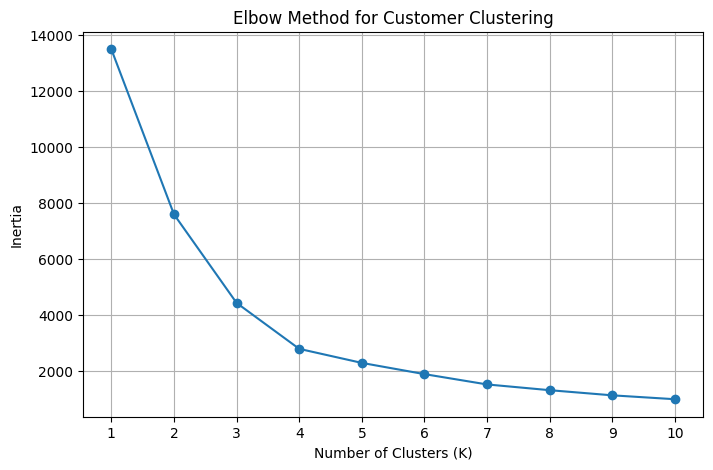

In [6]:
# STEP 6: APPLY THE ELBOW METHOD
# Purpose: Test different numbers of clusters and calculate inertia.
# Reason: Inertia measures the sum of squared distances between customers
# and their assigned cluster centres. We use the elbow graph to help select K.

from sklearn.cluster import KMeans

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Clustering")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:

# STEP 7: SELECT THE NUMBER OF CLUSTERS
# Purpose: Interpret the elbow graph and select a suitable K value.
# Reason: The curve appears to flatten after K=4, suggesting diminishing
# improvements in inertia when additional clusters are introduced.
# K=4 is our current candidate and will be assessed using the resulting segments.

from sklearn.cluster import KMeans

# Choose 4 clusters based on the elbow graph
chosen_k = 4

# Build and train the K-Means model
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the number of customers in each cluster
print("Number of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())


Number of customers in each cluster:
Cluster
0    1118
1    1914
2    1584
3    2125
Name: count, dtype: int64


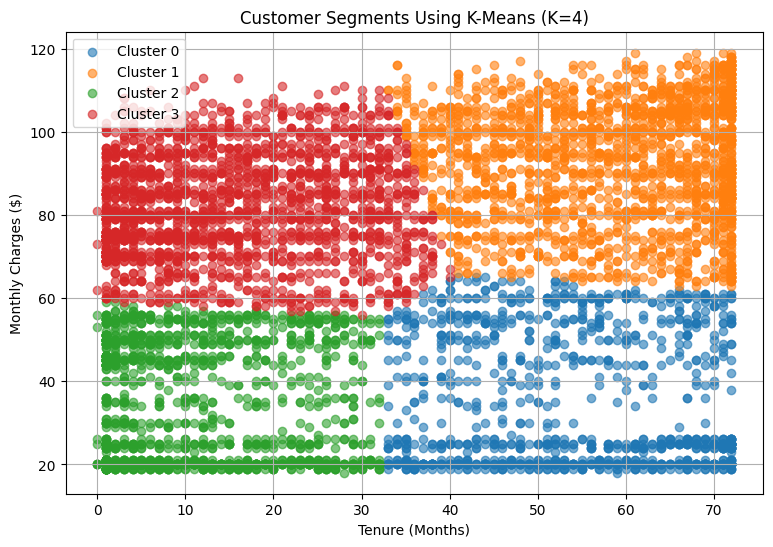

In [8]:

# STEP 8: TRAIN K-MEANS AND ASSIGN CLUSTER LABELS
# Purpose: Fit the K-Means algorithm using four clusters.
# Reason: Assign each customer to a group based on similarity in tenure
# and MonthlyCharges.

# VISUALISE CUSTOMER SEGMENTS
# Purpose: Plot customers according to tenure and MonthlyCharges.
# Reason: Visualisation helps us see how the four clusters are distributed
# and identify possible differences between customer segments.

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]

    plt.scatter(
        group["tenure"],
        group["MonthlyCharges"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.title("Customer Segments Using K-Means (K=4)")
plt.legend()
plt.grid(True)
plt.show()


In [9]:
# STEP 9: SUMMARISE CLUSTER CHARACTERISTICS
# Purpose: Calculate the number of customers and average feature values within each cluster.
# Reason: Compare customer segments using their typical tenure and monthly charges before assigning business interpretations.

cluster_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("tenure", "size"),
    Average_Tenure=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean")
).round(2)

cluster_summary


,Number_of_Customers,Average_Tenure,Average_Monthly_Charges
Cluster,,,
0,1118,54.02,34.54
1,1914,58.59,93.03
2,1584,11.23,33.84
3,2125,14.95,81.68


In [10]:
# STEP 10: ANALYSE CHURN BY CUSTOMER SEGMENT
# Purpose: Compare churn rates across the four clusters.
# Reason: Investigate whether particular customer segments have higher
# churn rates and may need targeted retention strategies.
# Note: Churn is analysed after clustering; it is not used to create clusters

churn_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("Churn", "size"),
    Churned_Customers=("Churn", lambda x: (x == 1).sum()),
    Average_Tenure=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean")
).round(2)

churn_summary["Churn_Rate_Percent"] = (
    churn_summary["Churned_Customers"]
    / churn_summary["Number_of_Customers"]
    * 100
).round(2)

churn_summary


,Number_of_Customers,Churned_Customers,Average_Tenure,Average_Monthly_Charges,Churn_Rate_Percent
Cluster,,,,,
0,1118,55,54.02,34.54,4.92
1,1914,303,58.59,93.03,15.83
2,1584,396,11.23,33.84,25.00
3,2125,1037,14.95,81.68,48.80


In [11]:
print(df["Churn"].value_counts())

Churn
0    4950
1    1791
Name: count, dtype: int64


In [12]:
# STEP 12: EXPORT CLUSTERING RESULTS
# Purpose: Save the customer dataset with the assigned cluster labels.
# Reason: Preserve the results for review, sharing with the project team, and use in the final report.

df.to_csv("Customer_Clusters_Results.csv", index=False)

from google.colab import files
files.download("Customer_Clusters_Results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>